<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/deep-learning/01_pytorch_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 ### pytorch workflow


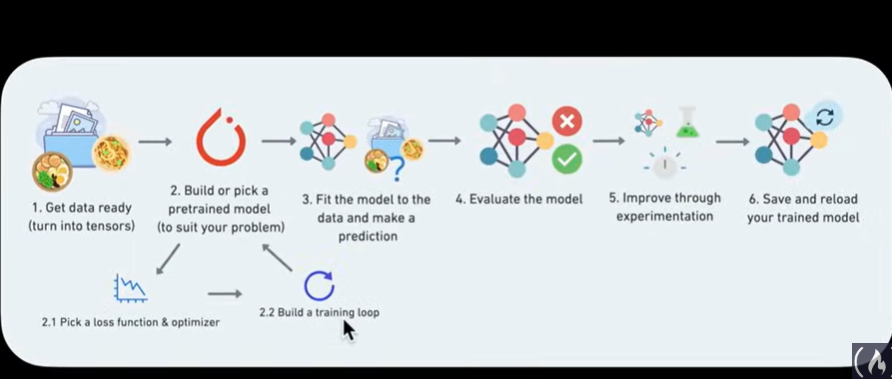

what_were_covering =

{
  
1. "data (prepare and load)",
2. "build model",
3. "fitting the model to data(training)",
4. "making predictions and evaluating a model (inferenece)",
5. "saving and loading a model",
6. "putting it all together"

}

https://docs.pytorch.org/docs/stable/nn.html

* check this out

In [ ]:
import torch
from torch import nn # nn con contains all of pytorch building blocks , nn means neural networks
import matplotlib.pyplot as plt

# check pytorch version
torch.__version__

'2.11.0+cpu'

## 1. data (preparing and loading)
 data can be almost anything... in machine learning

 * excel speadsheet
 * images of anykind
 * videos(youtube has lots of data..)
 * audio like songs or podcasts
 * DNA
 * text

 machine learning is a game of two parts:
 1. get data into numerical representation
 2. build a moodel to learn patterns in the numerical representation

  to showcase this, lets create some known  data using the linear regression formula .

  we'll use a linear regression formula to make a straight line with known parameters

  



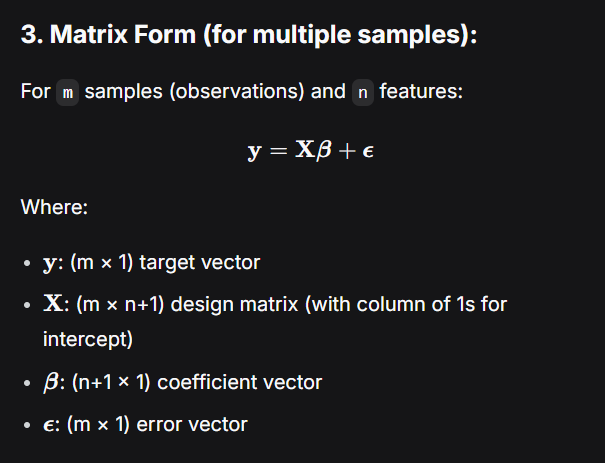

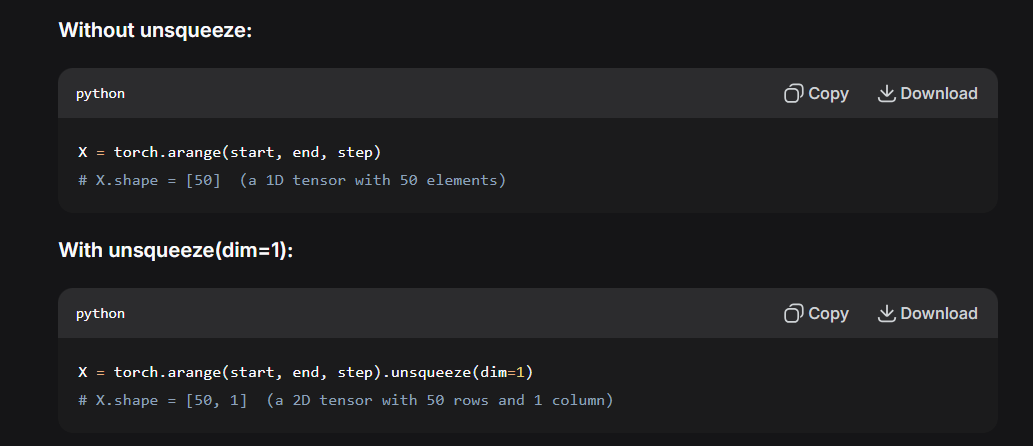

# weight
Definition:
A weight is a coefficient for an input feature. It determines the strength of the connection between two neurons. In simple terms, it tells the model how much influence a given input should have on the output.

If a weight is high, a small change in that input will cause a big change in the output (the input is considered very important).

If a weight is zero, the input is ignored.

If a weight is negative, an increase in the input will cause a decrease in the output (an inverse relationship).

# Bias
Analogy: Think of bias as the "baseline" or the "intercept." It allows the model to shift the activation function to better fit the data.

Definition:
Bias is an additional constant added to the calculation. It allows the model to fit the data even when all the inputs are zero. Without bias, the output of a neuron would always start from zero, which severely limits the model's flexibility.

Example:
Continuing the house price example:

Even if a house had 0 sq ft and was 0 years old (which is impossible in reality, but works for the math), the price can't be zero. There is a baseline cost of land or market minimum.

The bias term allows the model to learn that baseline price.

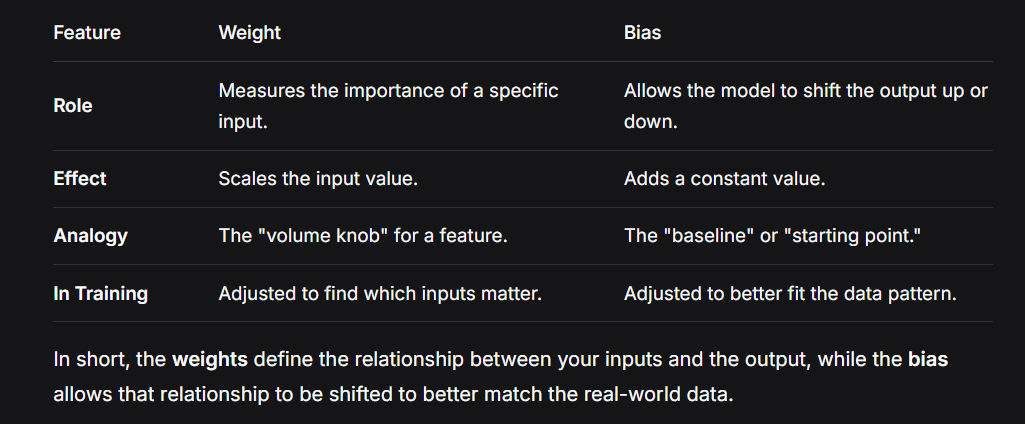

In [ ]:
# create a known parameters
weight = 0.7
bias = 0.3

# create
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim =1)
y = (weight * X) + bias

X[:10], y[:10], len(X), len(y)

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]),
 50,
 50)

### splitting data into three sets ,
1. training set
2. validation set
3. testing set

In [ ]:
# Training data (80% of total)
# X_train  # The INPUT features for training (40 houses: size, bedrooms, etc.)
# y_train  # The LABELS/ANSWERS for training (40 actual prices)

# Testing data (20% of total)
# X_test   # The INPUT features for testing (10 new houses the model hasn't seen)
# y_test   # The LABELS/ANSWERS for testing (10 actual prices to check against)

In [ ]:
# create a train/test split
train_split = int(0.8  * len(X))
X_train, y_train = X[:train_split], y[:train_split] #X[:train_split] - Takes all rows from index 0 up to (but not including) train_split from the features tensor.
X_test, y_test = X[train_split:],y[train_split:] #X[train_split:] - Takes all rows from index train_split to the end from X

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

### how might we better visualize our data?
 this is where the data explorer's motto comes in!

 visualize

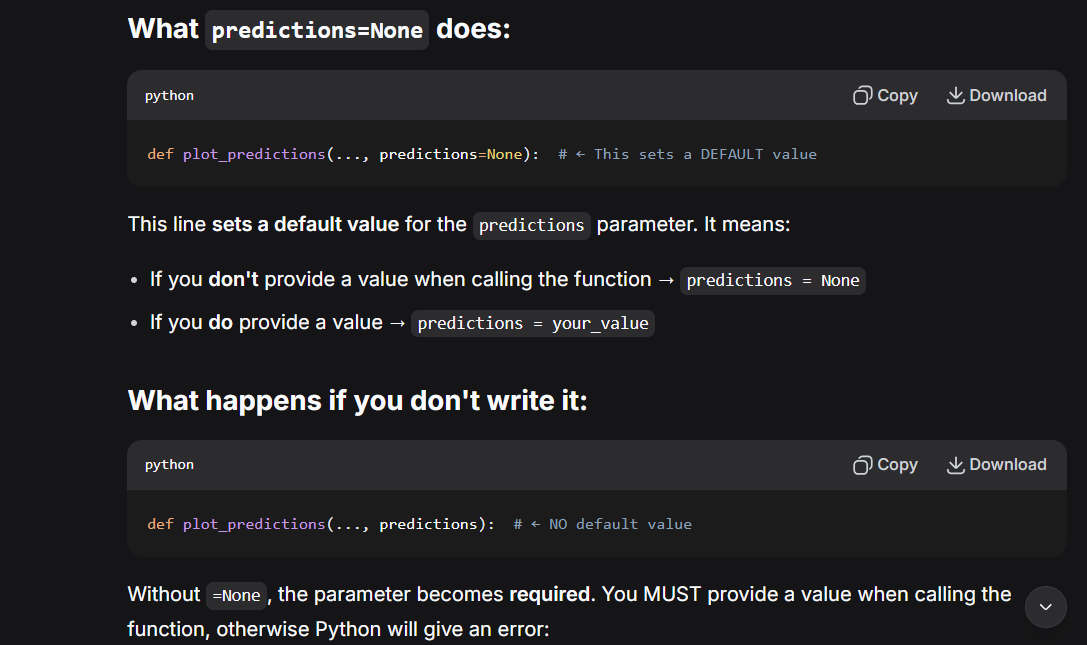

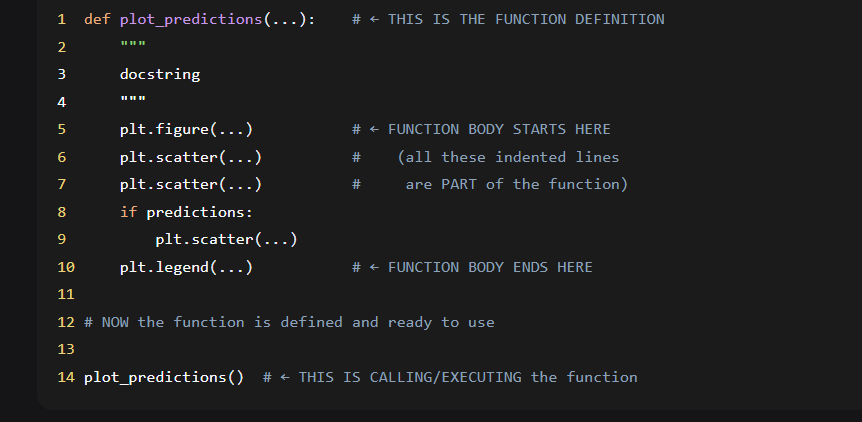

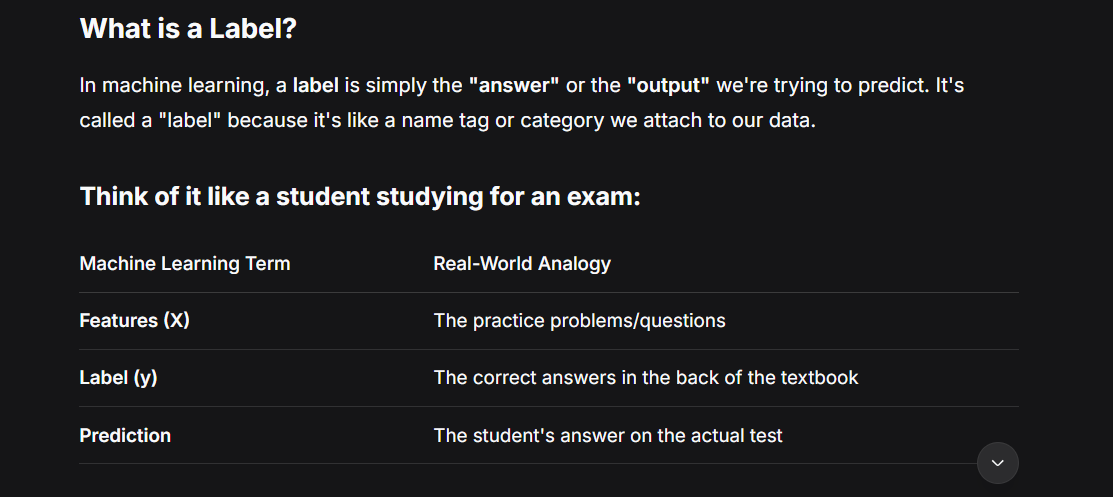

In [ ]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
  """
  plots training data, test data and compares predictions
  """
  plt.figure(figsize=(10,7)) #plt.figure() - Creates a new empty figure/window to draw on ,figsize=(10,7) - Sets the width to 10 inches and height to 7 inches

  #plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data") #plt.scatter() is a function that creates a scatter plot - it puts individual points on a graph based on their x and y coordinates.

  #plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data") #test_data → x-coordinates (position left/right) ,test_labels → y-coordinates (position up/down) ,c="g" → color = green ,s=4 → size = 4 pixels (dot size) ,label="Testing data" → name for the legend

  # are there predictions?
  if predictions is not None:
    # plot the predicitions if they exist
    plt.scatter(test_data, predictions, c="r", s=4, label="predicitions")

  plt.legend(prop={"size": 14}); # legend helps to  adds the little box on the graph showing what each color means (like a key/index).
# prop means proposties it sets the size of font etc

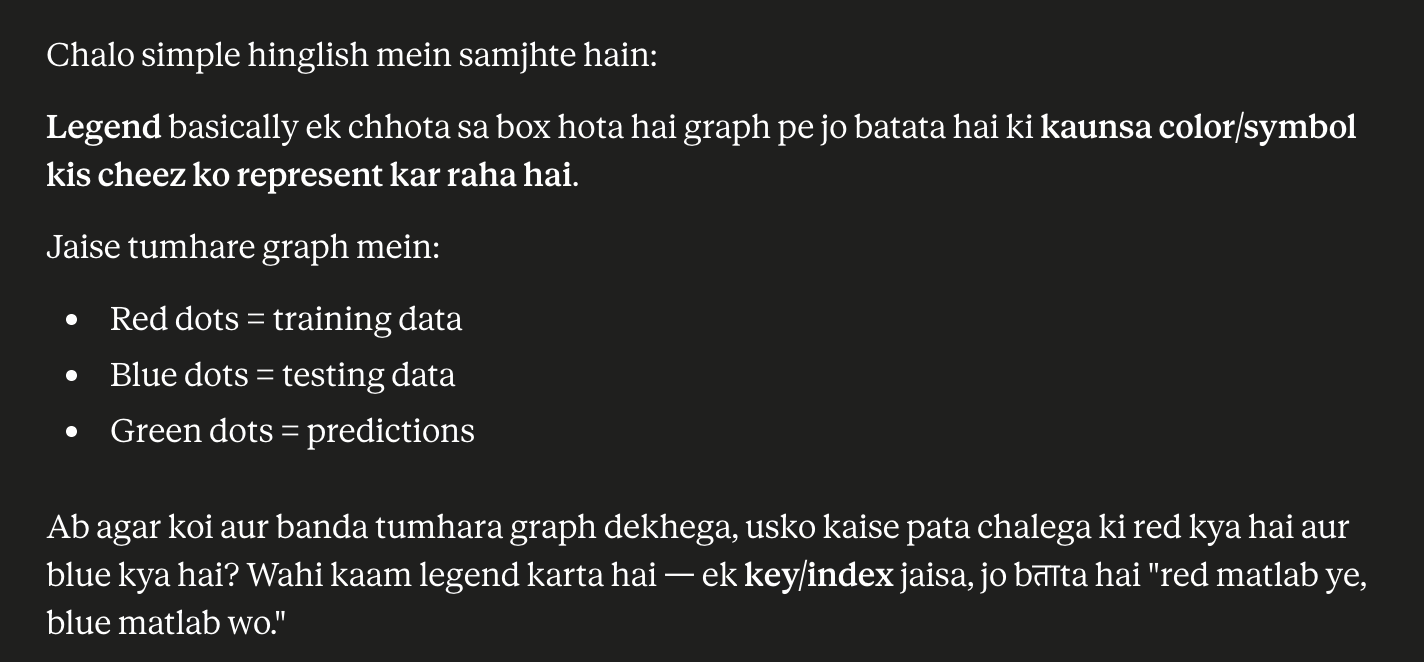

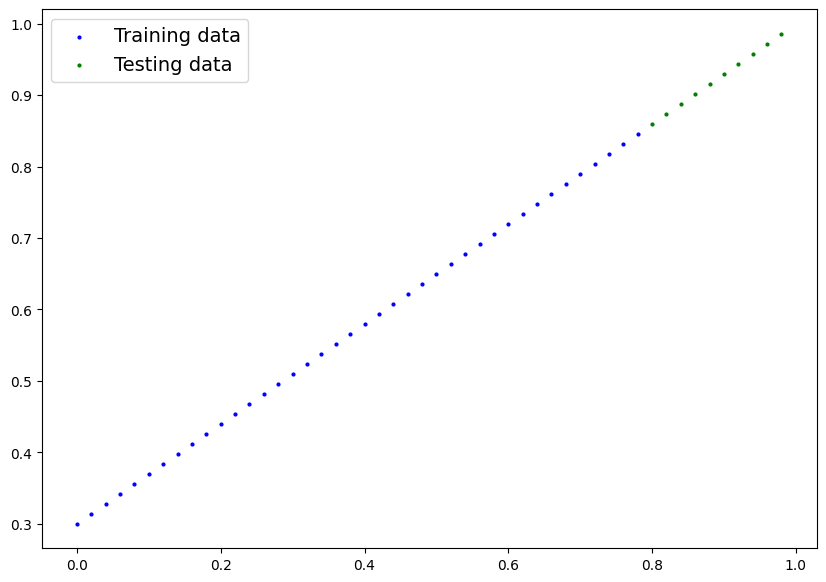

In [ ]:
plot_predictions()

### 2. BUILD MODEL

our first PYtorch model
* this is very exciting ... lets do it

becuase we're going to be buidling classes throughtout the course,
I'd recommend getting familiar with OOP in python , to do so you can use the following resource from real python : https://realpython.com/python-classes/

what our model does:
* start with random values(weights and biases)
* look at trainign data and adjust  the random values to better represent (or get closer to) the ideal vales (the weight and bias vlaues we used to create the  data)

how does it do so

through two main algorithms:
1. gradient descent
2. Backpropogation

# Gradient descent


*Idea:
Gradient Descent is an optimization method used to minimize error (loss) in machine learning models by adjusting parameters (weights).

Simple intuition:
Imagine standing on a hill in fog and trying to reach the lowest point.
You:

1. Check slope direction
2. Step downhill
3. Repeat until you reach bottom

Math intuition:
We update weights like this:

W = W - Alpha * (AlphaLoss/Alpha*W)

Where:

W → weight

α (alpha) → learning rate (step size)

∂Loss/∂W → gradient (slope)

Key concept:

Large learning rate → may overshoot minimum

Small learning rate → slow but stable


# backpropogation
Idea: Backpropagation is the method used to calculate gradients in neural networks so Gradient Descent can update weights.

Flow in training neural network:

Step 1 — Forward Pass

Input → Hidden layers → Output → Calculate Loss

Step 2 — Backward Pass

Loss → propagate error backward → compute gradients

Step 3 — Update Weights

Use Gradient Descent to adjust weights


Real Example (Neural Network Training)
1. Predict house price
2. Compare with actual price → loss
3. Backprop → find which neurons caused error
4. Gradient Descent → adjust weights
5. Repeat → model improves

One-Line Memory Trick

Gradient Descent = How to update weights- https://youtu.be/IHZwWFHWa-w

Backpropagation = How to compute gradients- https://youtu.be/IIg3gGewQ5U

A gradient measures the steepness, incline, or rate of change of a line or curve, defined as the ratio of vertical change ("rise") to horizontal change ("run"). Commonly known as the slope ,it represents how much a dependent variable changes relative to an independent variable.

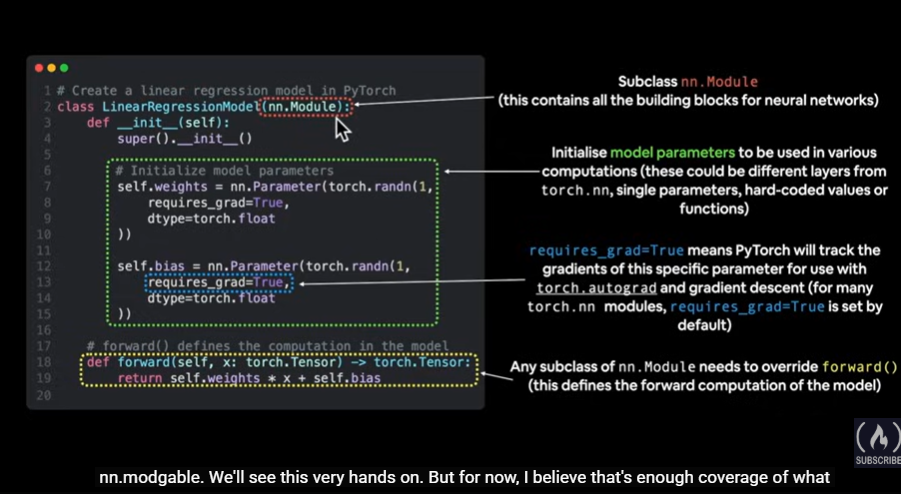

In [ ]:
from torch import nn

#create linear regression model class
class LinearRegressionModel(nn.Module): # <- almost everything in python
  def __init__(self):
    super().__init__()#Calls the parent class (nn.Module) constructor. Required to properly initialize the inherited PyTorch functionality.  super ← Calls the parent's __init__ method,
    self.weights = nn.Parameter(torch.randn(1,
                                            requires_grad =True,# https://docs.pytorch.org/docs/stable/generated/torch.nn.parameter.Parameter.html
                                            dtype= torch.float32))
    self.bias = nn.Parameter(torch.randn(1,
                                         requires_grad=True,
                                         dtype=torch.float))
  # forward method to define the computation in the model
  def forward(self, x: torch.Tensor) -> torch.Tensor: #"x" is at the input data training
    return self.weights * x + self.bias # This is the linear regression formula: y = weight * x + bias

#  self.weights * x - Multiply the learnable weight parameter by the input data
#  + self.bias - Add the learnable bias parameter


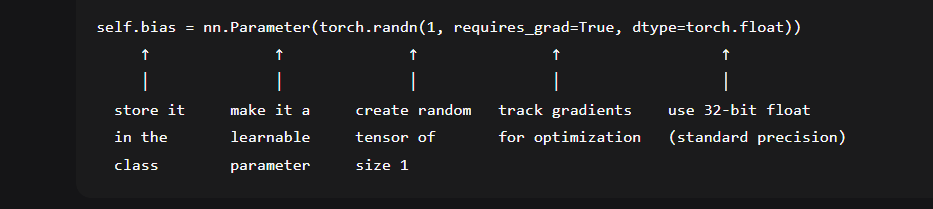

### pytorch model building essentials
* torch.nn - contains all of the buildings for computational graph (a neural netwoks can be considered)
* torch.nn.Parameter - what parameters should our model try and learn , often a pytorch layer from torch.nn will set these  for us
* torch.nn.Module - baseclass for all neural network moduels , if you subclass it , you should overwrite forward()
* torch.optim - this where the optimizers in pytorch live ,they will help with gradient descent
* def forward () - all nn.module subclasses requires u to iverwrite forward() , this method defines what happens in the forward computation


* see more https://www.learnpytorch.io/pytorch_cheatsheet/

### nn.parameter

* What is nn.Parameter?

-> nn.Parameter is a special tensor that tells PyTorch: "This tensor should be considered a learnable parameter in my model!"

* What does it do?

->  When you wrap a tensor with nn.Parameter, it automatically:

1. Adds itself to the model's list of parameters (accessible via model.parameters())

2. Tells PyTorch to calculate gradients for it during backpropagation

3. Gets updated automatically during optimization

Without building blocks (doing everything yourself):

In [ ]:
# You'd have to manually handle:
# - Storing parameters
# - Tracking which tensors are learnable
# - Moving models to GPU
# - Saving/loading models
# - Gradient calculations
# - And much more...

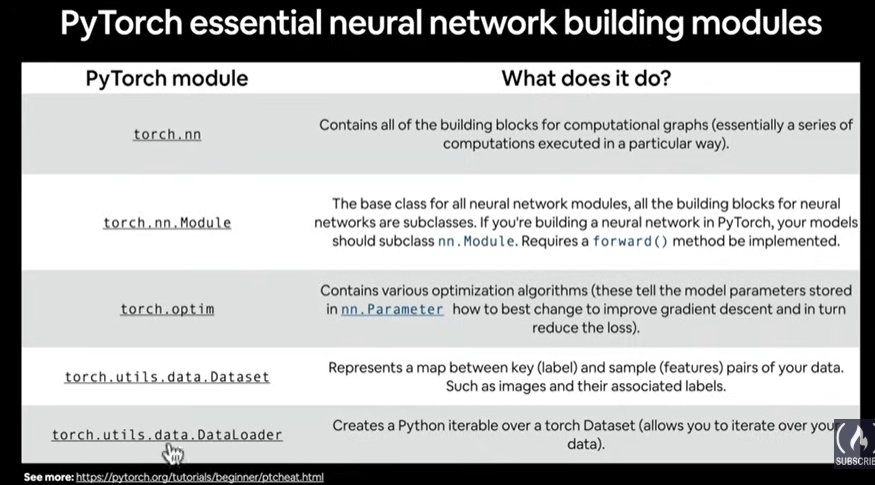

### chechking the contents of our pytorch model

1. now we've created a model , lets see what is inside
2. so we can check our model parameters or what using inside our model using .parameters()

In [ ]:
torch.randn(1)

tensor([-0.5396])

#### .manual_seed()  

What it does:

* It fixes the random number generator so that all future random operations produce the same sequence of "random" numbers every time you run your code
1. for example

torch.manual_seed(42)

 Run 1
* torch.randn(1)  # tensor([1.5410])
* torch.randn(1)  # tensor([-0.2934])
* torch.randn(1)  # tensor([-2.1788])

 Run 2 (restart kernel, run same code)
* torch.manual_seed(42)
* torch.randn(1)  # tensor([1.5410])  ← Same!
* torch.randn(1)  # tensor([-0.2934]) ← Same!
* torch.randn(1)  # tensor([-2.1788]) ← Same!

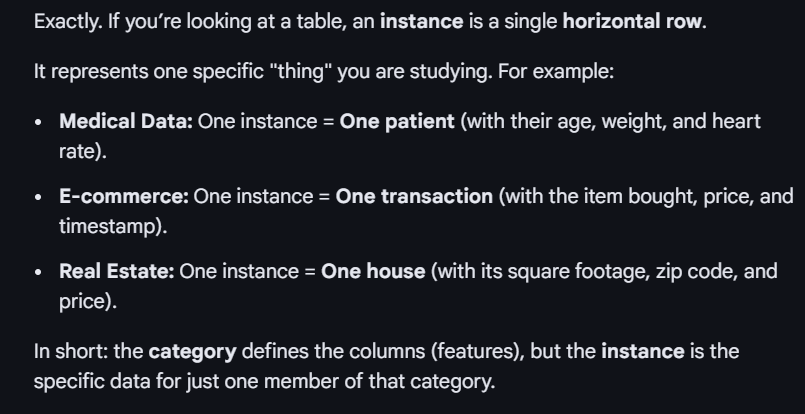

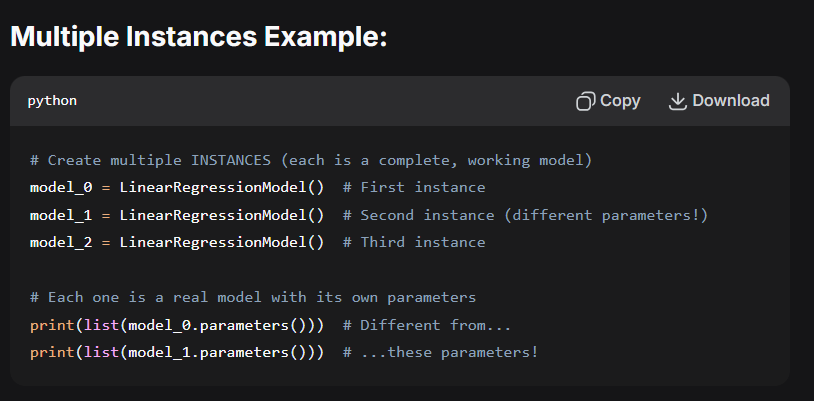

In [ ]:
#create a random seed
torch.manual_seed(42) #  .manual_seed() - a method in the PyTorch library , Sets seed for CPU

#create an instance of the model (this is a subclass of nn.module )
model_0 = LinearRegressionModel()

list(model_0.parameters())


[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

list(model_0.parameters())

Returns a LIST containing:

  tensor([0.3367]),  ← 1st element (weights)

  tensor([0.1288])    ← 2nd element (bias)


In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

tbr
* requires_grad=True tells PyTorch to track all operations on this tensor so it can calculate gradients (derivatives) during backpropagation. This is essential for training neural networks!

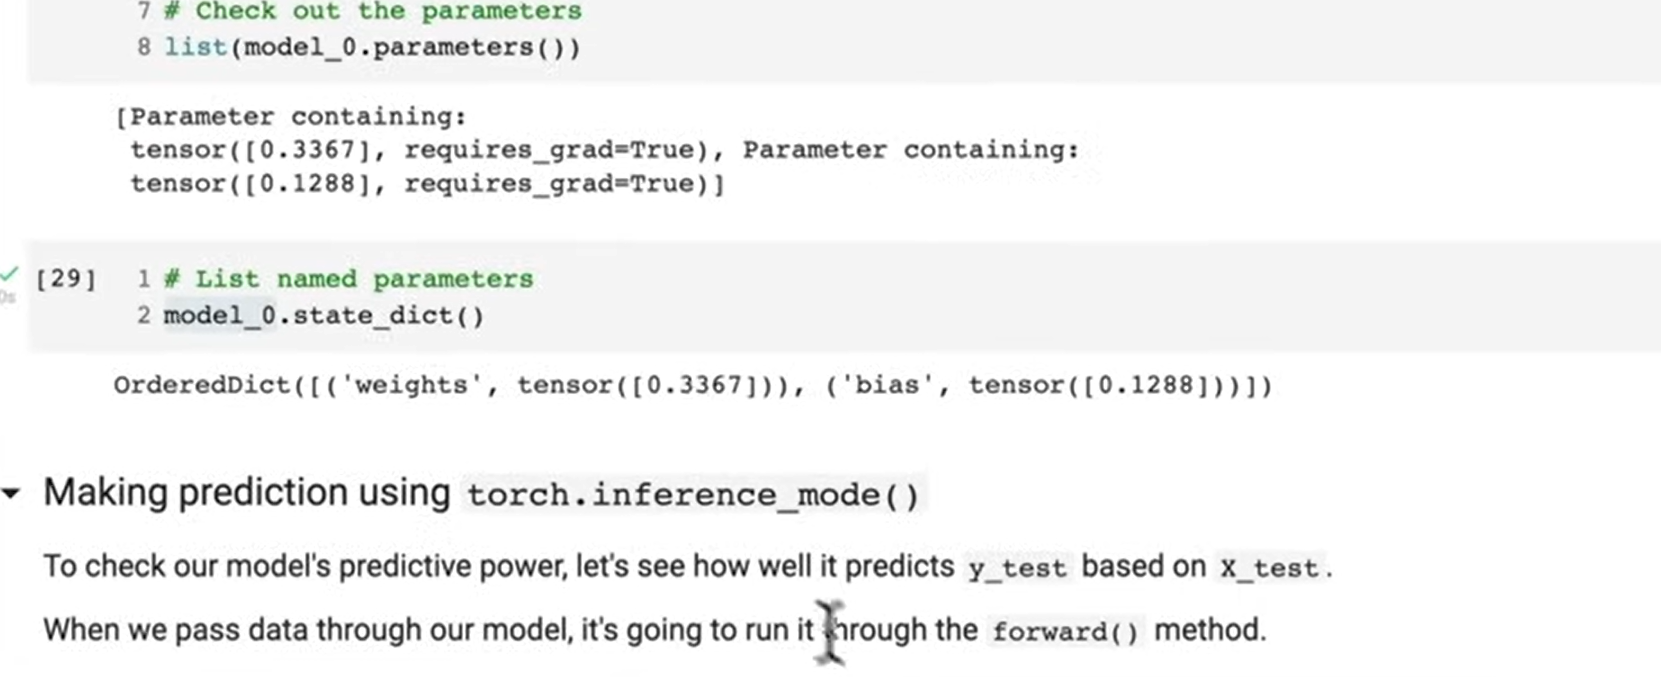

.state_dict()

* is a method that returns a dictionary containing all the model's parameters (weights and biases) with their current values. It's like taking a "snapshot" of your model's learned parameters.

In [ ]:
X_test, y_test

(tensor([[0.8000],
         [0.8200],
         [0.8400],
         [0.8600],
         [0.8800],
         [0.9000],
         [0.9200],
         [0.9400],
         [0.9600],
         [0.9800]]),
 tensor([[0.8600],
         [0.8740],
         [0.8880],
         [0.9020],
         [0.9160],
         [0.9300],
         [0.9440],
         [0.9580],
         [0.9720],
         [0.9860]]))

In [ ]:
#make predicitons  with model
with torch.inference_mode():
  y_preds = model_0(X_test)

# with torch.no_grad():
#   y_preds= model_0(X_test)
# you can do something similar with torch.no_grad(), however, torch.inference_mode() is preferred

y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

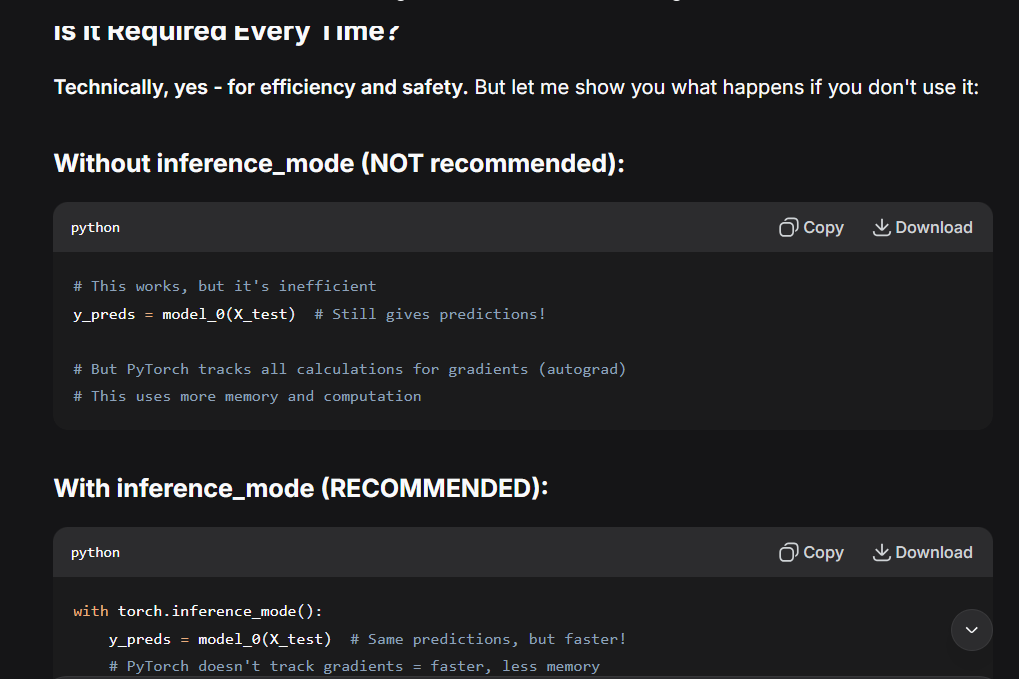

### We have:
* X_test  = [house1_features, house2_features, house3_features]  # What we know
* y_test  = [300000, 450000, 275000]                              # What we WANT to predict

# Model does:
y_preds = model(X_test)  # Uses X_test to PREDICT y_test

# Goal:
y_preds ≈ y_test  # Make predictions as close as possible to true values

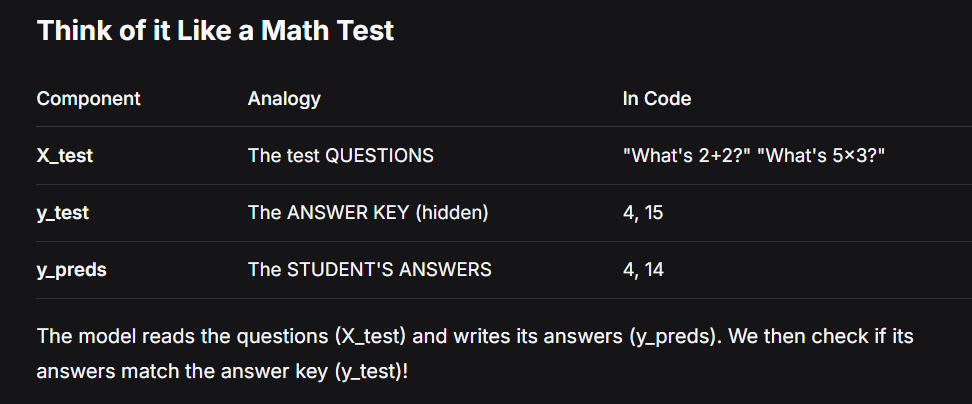

Both torch.inference_mode() and torch.no_grad() are used for making predictions, but they have important differences. Let me explain:

1.  What they both do:
* Disable gradient tracking (saves memory and computation)

* Make the model faster for predictions

* Used when you don't want to train, just make predictions

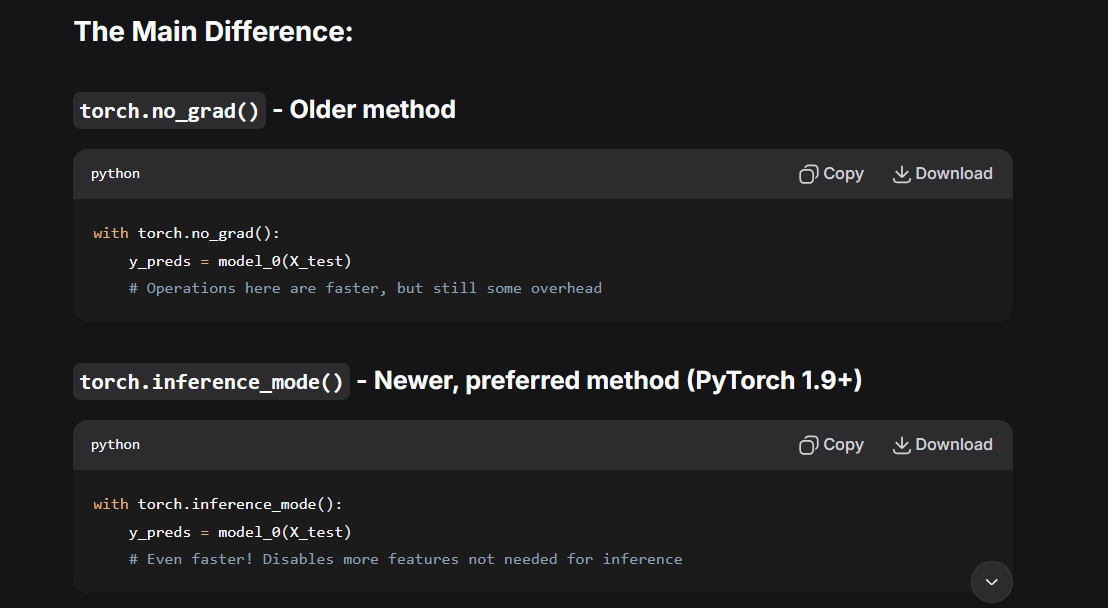

look more for pytorch inference mode on twitter

In [ ]:
y_test

tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

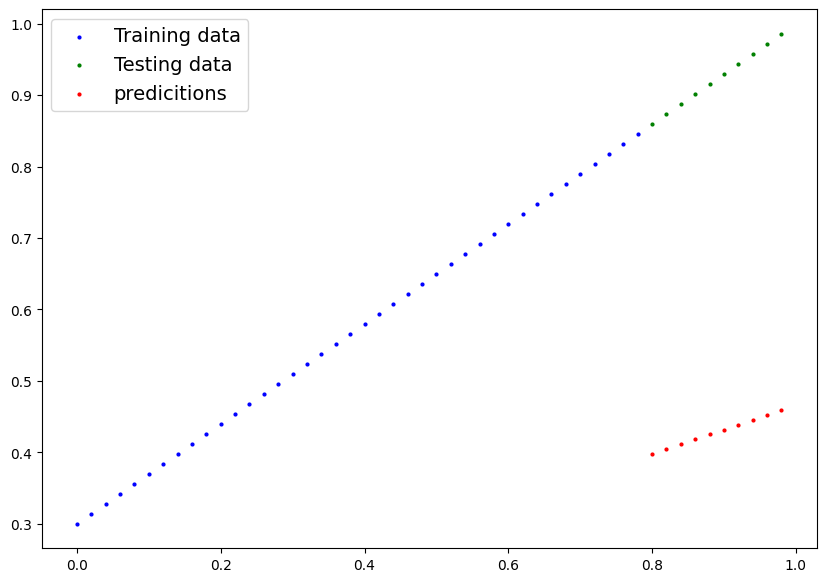

In [ ]:
plot_predictions(predictions= y_preds)

### Train model

the model idea of training is  for a model to move fro some unknown parameters (these may be random) to soem known parameters

or in other words from a poor representationn of the data to be a better representation of the data

to measure how good ur model predictions are is to use loss function

*note : loss function may also  be called cost function or criterion in different areas. for our case , we are going to refer to it as a loss function

things need to train


*   **loss function **a function to measure  how rong your models predictions are to ideal outputs , lower is better
*  **optimizer ** takes into account the loss of a model and ajusts the model paramater (eg. weigh and biases) to improve the function

and specifiacally for pytorch we need
* a training loop
* a testing loop


In [ ]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
# check out our models's parameters (a parameter is a value that the model sets itself)
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

https://docs.pytorch.org/docs/stable/optim.html

https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html

In [ ]:
# setup a loss function
loss_fn = nn.L1Loss()

# setup of optimizer (stochastic gradient descent)
optimizer = torch.optim.SGD(params = model_0.parameters(),
                            lr= 0.01) # lr = learning rate = possibly the most important hyperparameter you can set , the common value of lr is 0.01

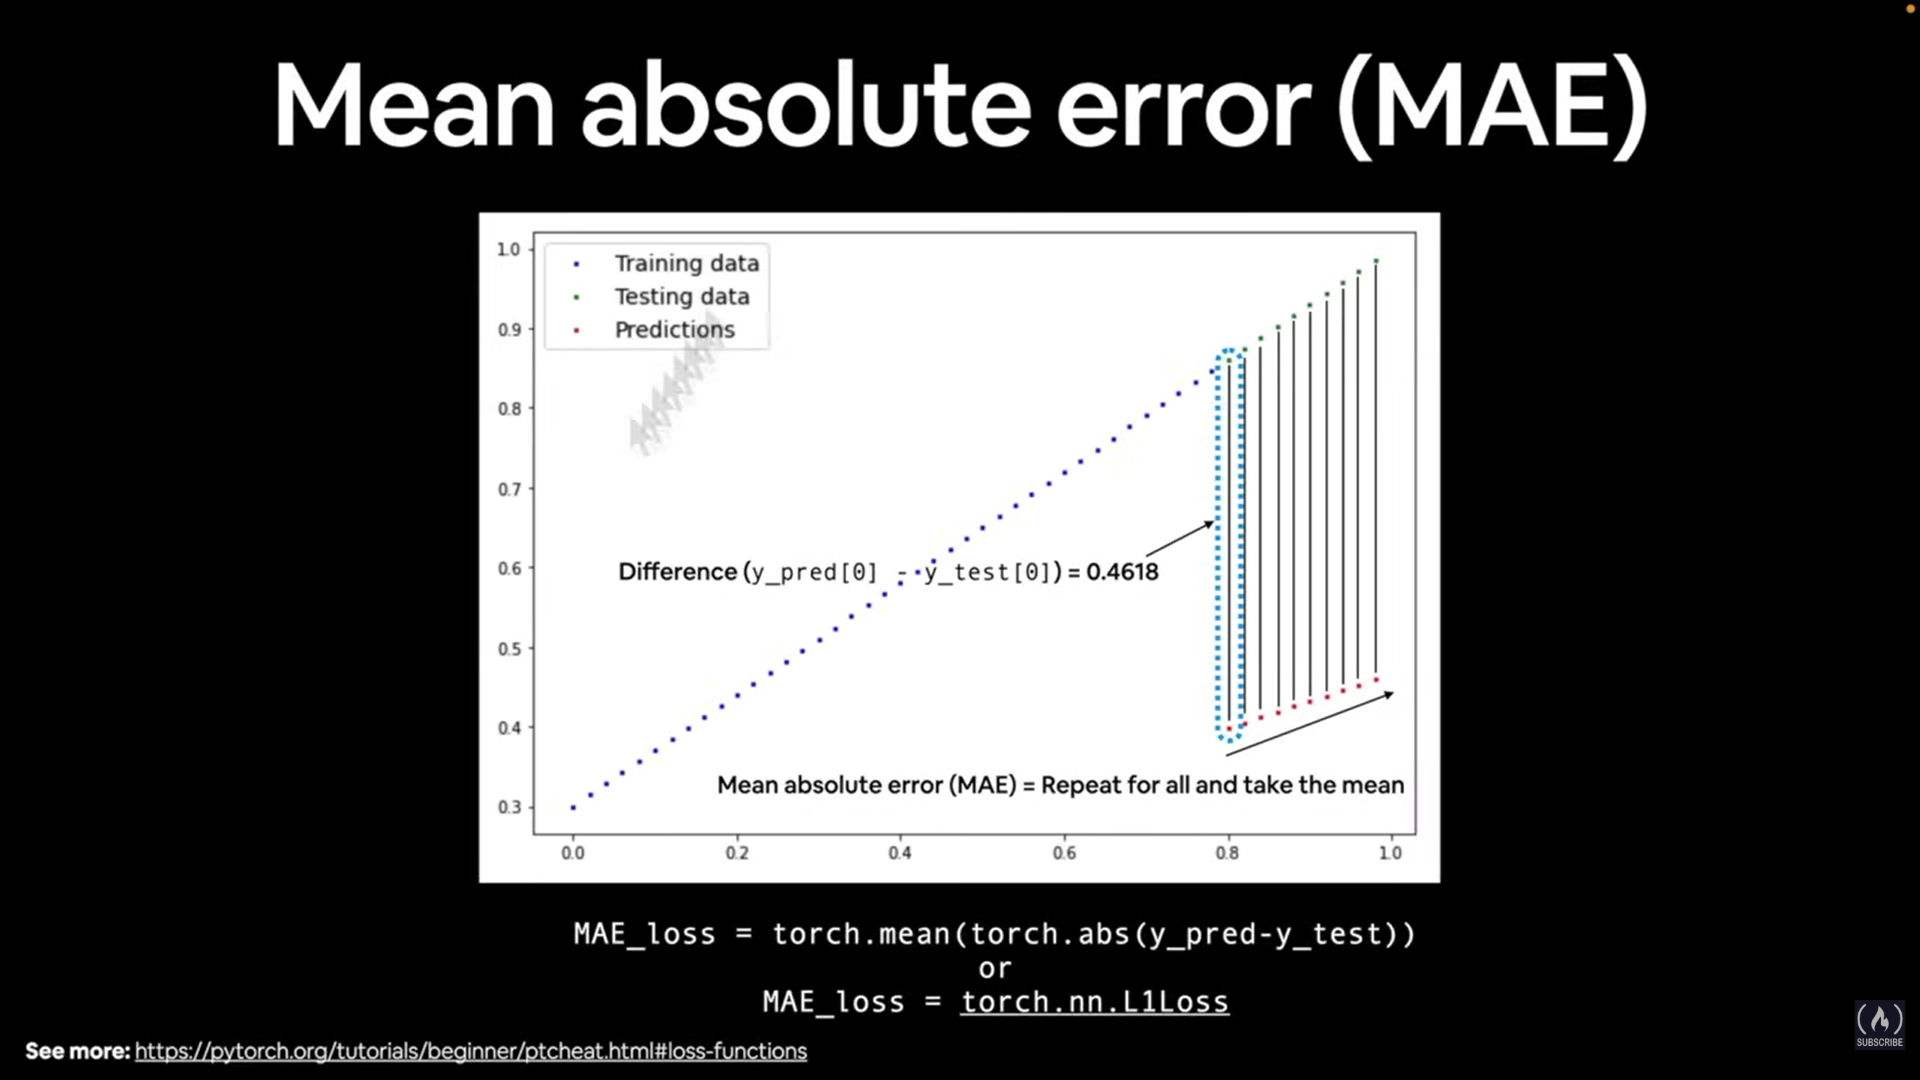

Q : which loss function should i use ?

A : this will be problem specific. but with experience , you will get a idea of what works and what doesnt with your particular problem set .

for example, for regression problem (like ours )  a loss function of nn.L1Loss () and an optimizer like torch.optim.SGD() will suffice.

But for a classification problem like classifying whether a photo is of a dog or cat , you will likely want to use a loss function of nn.BCELoss() (binary cross entropy loss).

### building a training loop ( a testing loop ) in pytorch


a couple of things  we need in a training loop:
0. loop through the data
1. Forward pass (this involves data moving through our model's forward () functions ) - also called forward propogation

2. calculate the loss(compares forward pass predictions to ground truth labels)
3. optimizer zero grad
4. loss backward - move backward through the network to calculate the gradients of each paramaters with respect to the loss (** backpropogation** )
5. optimizer step - use the optimizer to adjust the model's paramters to try and improve the loss (** gradient descent **)

In [ ]:
with torch.no_grad():
  list(model_0.parameters())

In [ ]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

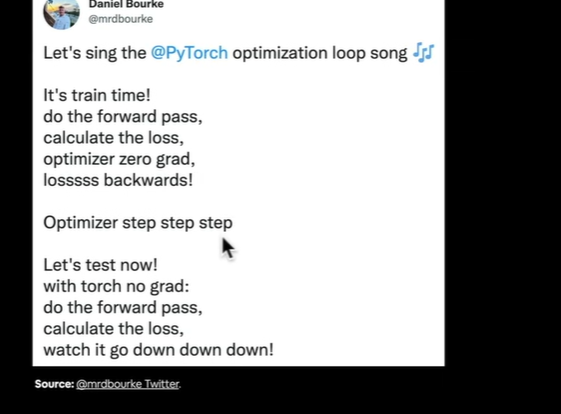

gradient is the step or slope

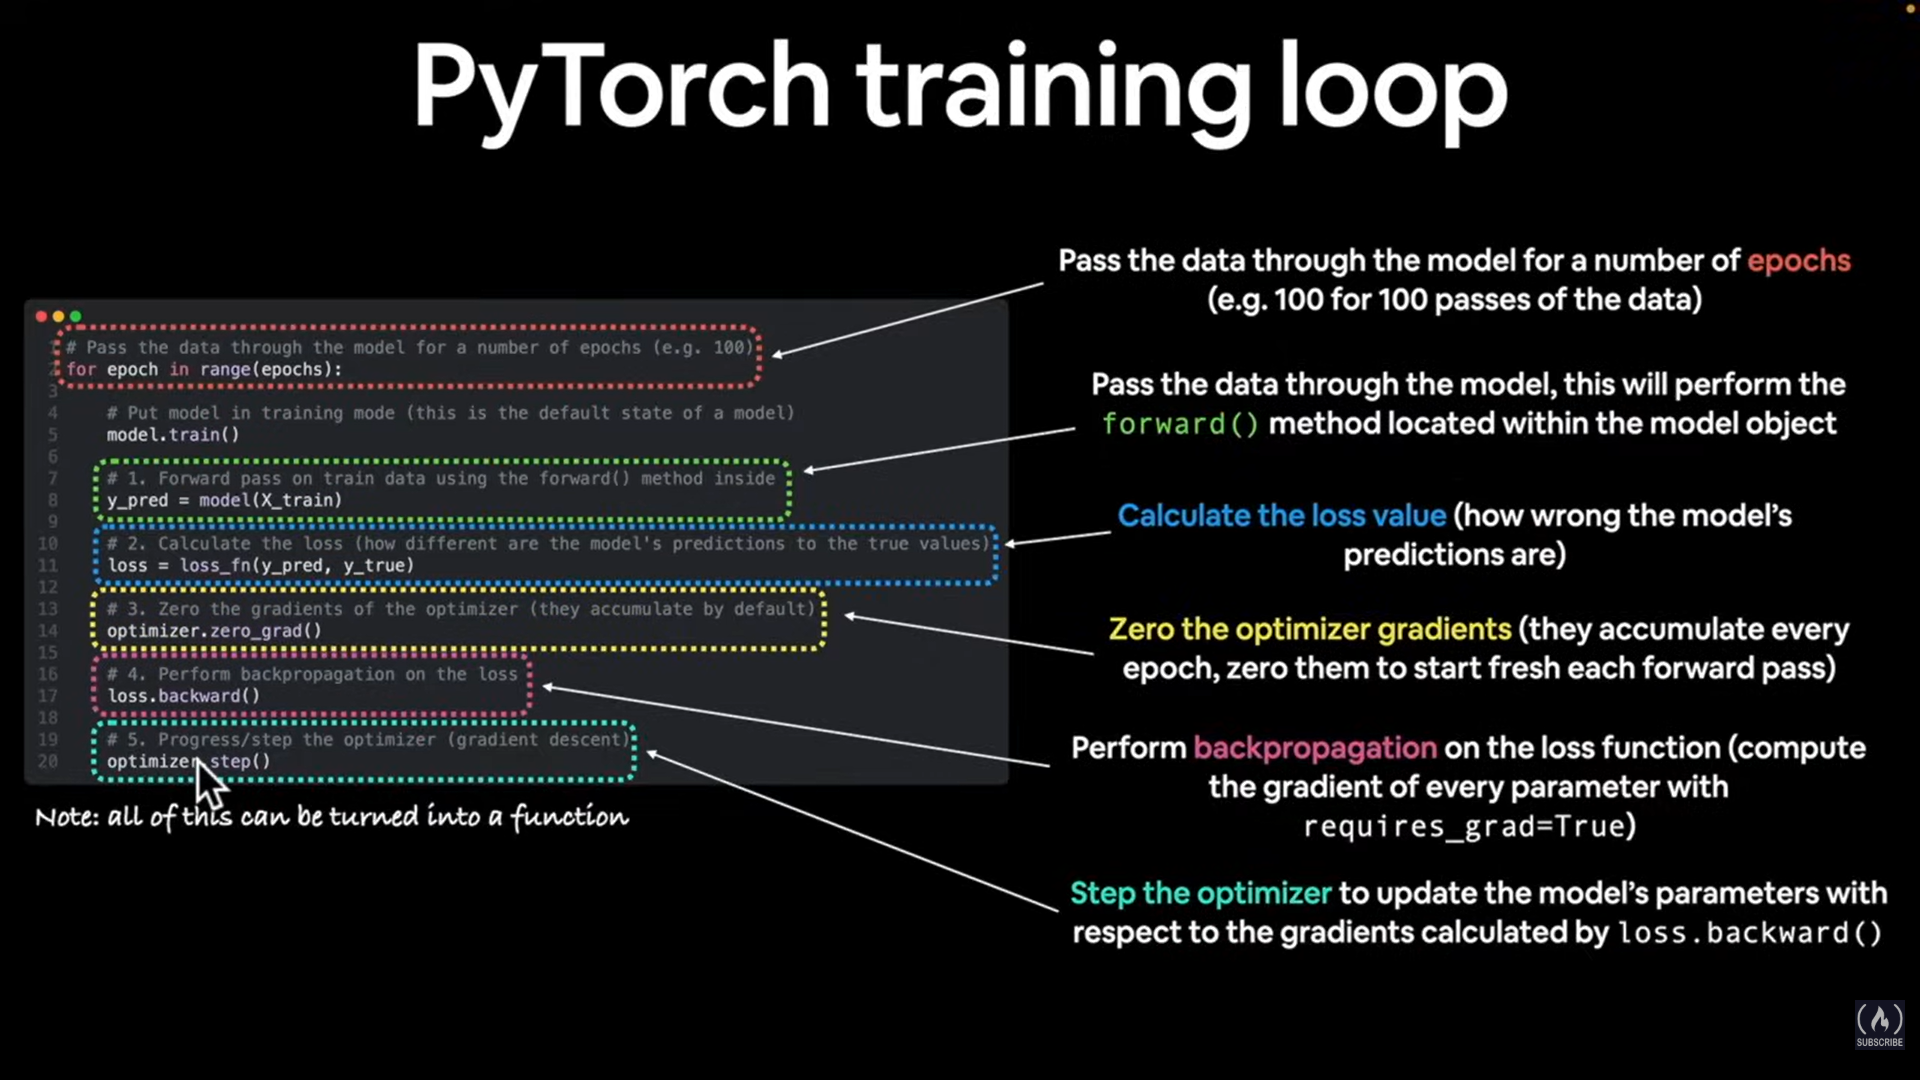

In [ ]:
torch.manual_seed(42)

# an epoch is one loop through the data ....(this is an hyperparameter because we've set it ourselves )
epochs = 100
epoch_count = []
loss_values = []
test_loss_values = []
### training
# 0. loop through the data
for epoch in range (epochs): # set the model to training mode
  model_0.train() # train mode in pytorch sets all parameters that require gradients to require gradients

  # 1. forward pass
  y_pred = model_0(X_train)

  # 2. calculate the loss
  loss = loss_fn(y_pred , y_train)
  print(f"loss: {loss}")

  # 3. optimizer zero grad
  optimizer.zero_grad()

  # 4. forward backprop on the loss with respect to the parameters of the model
  loss.backward()

  # 5. step the optimizer (performs gradient descent)
  optimizer.step() # by defualt how the optimizer changes will accumulate through the loop so.. we have to zero then above in step 3 for the next iteration of the loop

  #testing
  model_0.eval() # turns off different settings in the model not needed for evaluation/testing (dropout/batch norm layers )
  with torch.inference_mode():# turns off gradient tracking & a couple more things behind the scenes
  # with torch.no_grad():# you may also see torch.no_grad() in older pytorch code
    # 1. do the forward pass
    test_pred = model_0(X_test)

    #2. calculate the loss
    test_loss = loss_fn(test_pred , y_test)

  if epoch % 10 == 0 :
    epoch_count.append(epoch)
    loss_values.append(loss)
    test_loss_values.append(test_loss)
    print(f"epoch: {epoch} | test : {loss} | test loss : {test_loss}")
    # print out model state_dict()
    print(model_0.state_dict())

loss: 0.31288138031959534
epoch: 0 | test : 0.31288138031959534 | test loss : 0.48106518387794495
OrderedDict({'weights': tensor([0.3406]), 'bias': tensor([0.1388])})
loss: 0.3013603389263153
loss: 0.28983935713768005
loss: 0.2783183455467224
loss: 0.26679736375808716
loss: 0.2552763521671295
loss: 0.24375534057617188
loss: 0.23223432898521423
loss: 0.22071333229541779
loss: 0.20919232070446014
loss: 0.1976713240146637
epoch: 10 | test : 0.1976713240146637 | test loss : 0.3463551998138428
OrderedDict({'weights': tensor([0.3796]), 'bias': tensor([0.2388])})
loss: 0.18615034222602844
loss: 0.1746293306350708
loss: 0.16310831904411316
loss: 0.1515873372554779
loss: 0.14006635546684265
loss: 0.1285453587770462
loss: 0.11702437698841095
loss: 0.1060912236571312
loss: 0.09681284427642822
loss: 0.08908725529909134
epoch: 20 | test : 0.08908725529909134 | test loss : 0.21729660034179688
OrderedDict({'weights': tensor([0.4184]), 'bias': tensor([0.3333])})
loss: 0.08227583020925522
loss: 0.07638

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
np.array(torch.tensor(loss_values).cpu().numpy()), test_loss_values

/tmp/ipykernel_3568/3902306464.py:3: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  np.array(torch.tensor(loss_values).cpu().numpy()), test_loss_values


(array([0.31288138, 0.19767132, 0.08908726, 0.05314853, 0.04543797,
        0.04167863, 0.03818933, 0.0347609 , 0.03132383, 0.0278874 ],
       dtype=float32),
 [tensor(0.4811),
  tensor(0.3464),
  tensor(0.2173),
  tensor(0.1446),
  tensor(0.1136),
  tensor(0.0992),
  tensor(0.0889),
  tensor(0.0806),
  tensor(0.0723),
  tensor(0.0647)])

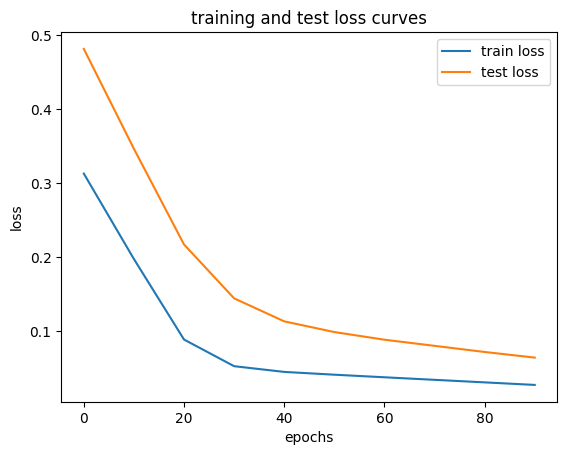

In [ ]:
#plot the loss curves
plt.plot(epoch_count, np.array(torch.tensor(loss_values).numpy()), label = "train loss")
plt.plot(epoch_count, test_loss_values , label = "test loss")
plt.title("training and test loss curves")
plt.ylabel("loss")
plt.xlabel("epochs")
plt.legend()

In [ ]:
with torch.inference_mode():
  y_preds_new = model_0(X_test)

In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.5784])), ('bias', tensor([0.3513]))])

In [ ]:
weight,bias

(0.7, 0.3)

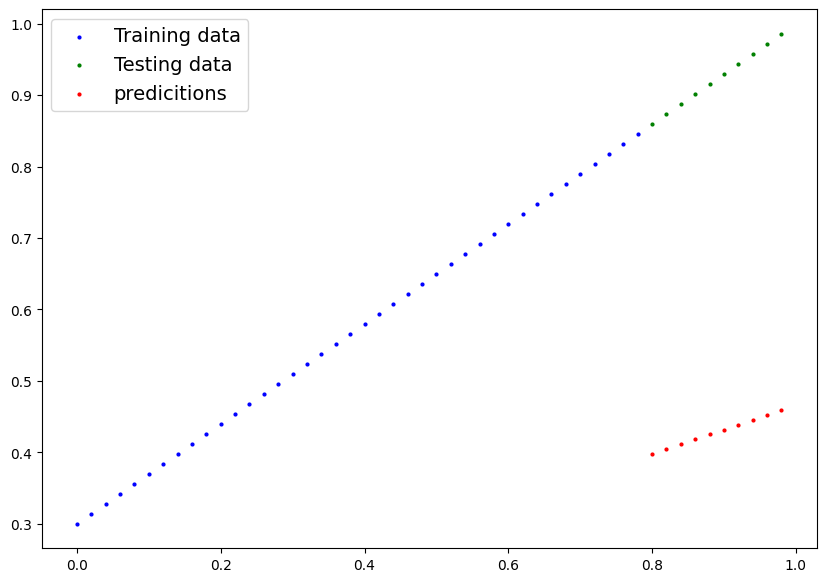

In [ ]:
plot_predictions(predictions=y_preds)

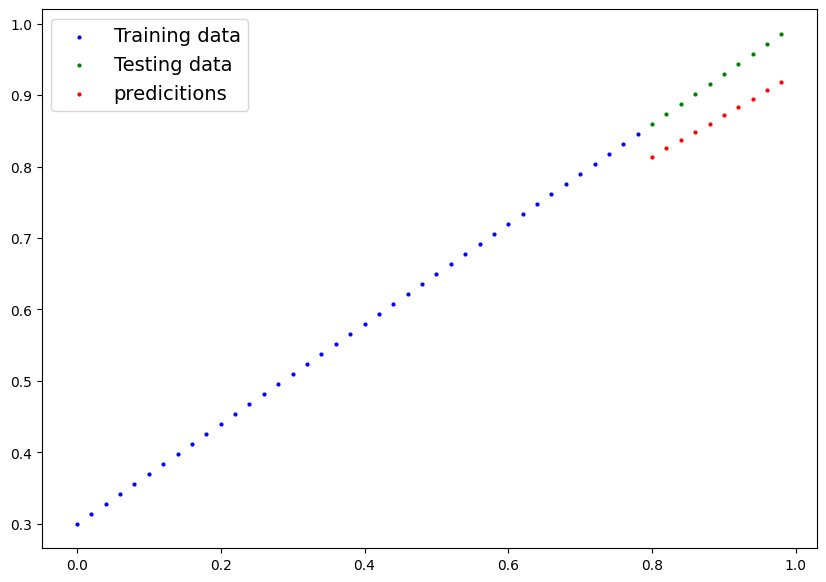

In [ ]:
plot_predictions(predictions=y_preds_new);

# saving a model in pytorch

there are three main methods uu should know about for saving and loading models in pytorch .

1. `torch.save()` - allows you save a pytorch object in python's pickle format
2. `torch.load()` - allows u load a saved pytorch object
3. torch.nn.Module.load_state.dict() - this allows to load a model's saved state dictionary

https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html

In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.5784])), ('bias', tensor([0.3513]))])

Method 1: Save the Colab Notebook File
The easiest way to save your notebook and its content is by using the Colab menu options.
Name your file in Google Colab.
Go to the File menu.
Select Save a copy in Drive. This saves a version of the notebook file (.ipynb) to a new folder named "Colab Notebooks" in your Google Drive

In [ ]:
# Saving our Pytorch model
from pathlib import Path
import torch

# Create model directory
MODEL_PATH = Path("model")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# Define model name and save path
MODEL_NAME = "01_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(), f=MODEL_SAVE_PATH)  # Removed quotes around MODEL_SAVE_PATH

Saving model to: model/01_pytorch_workflow_model_0.pth


In [ ]:
!ls -1 model

01_pytorch_workflow_model_0.pth


In [ ]:
model_0

LinearRegressionModel()

### Loading a Pytorch model

Since we saved our model's `state_dict()` rather the entire model, we'll create a new instance of our model class and load the saved state_dict() into that

In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.5784])), ('bias', tensor([0.3513]))])

In [ ]:
# to load in a saved state_dict we have to instances a new instance of our model class
loaded_model_0 = LinearRegressionModel()

#load the saved state_dict of model_0 (this will update the new instance with updated paramateres )
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [ ]:
loaded_model_0.state_dict()

OrderedDict([('weights', tensor([0.5784])), ('bias', tensor([0.3513]))])

In [ ]:
# make some predicitons with out loaded model
loaded_model_0.eval()
with torch.inference_mode():
  loaded_model_preds = loaded_model_0(X_test)

loaded_model_preds

tensor([[0.8141],
        [0.8256],
        [0.8372],
        [0.8488],
        [0.8603],
        [0.8719],
        [0.8835],
        [0.8950],
        [0.9066],
        [0.9182]])

In [ ]:
# Make some models preds
model_0.eval()
with torch.inference_mode():
  y_preds = model_0(X_test)

y_preds

tensor([[0.8141],
        [0.8256],
        [0.8372],
        [0.8488],
        [0.8603],
        [0.8719],
        [0.8835],
        [0.8950],
        [0.9066],
        [0.9182]])

In [ ]:
# compare loaded model preds with original model preds
y_preds == loaded_model_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

## 6. putting it all together

lets go back through the steps above and see it all in one place


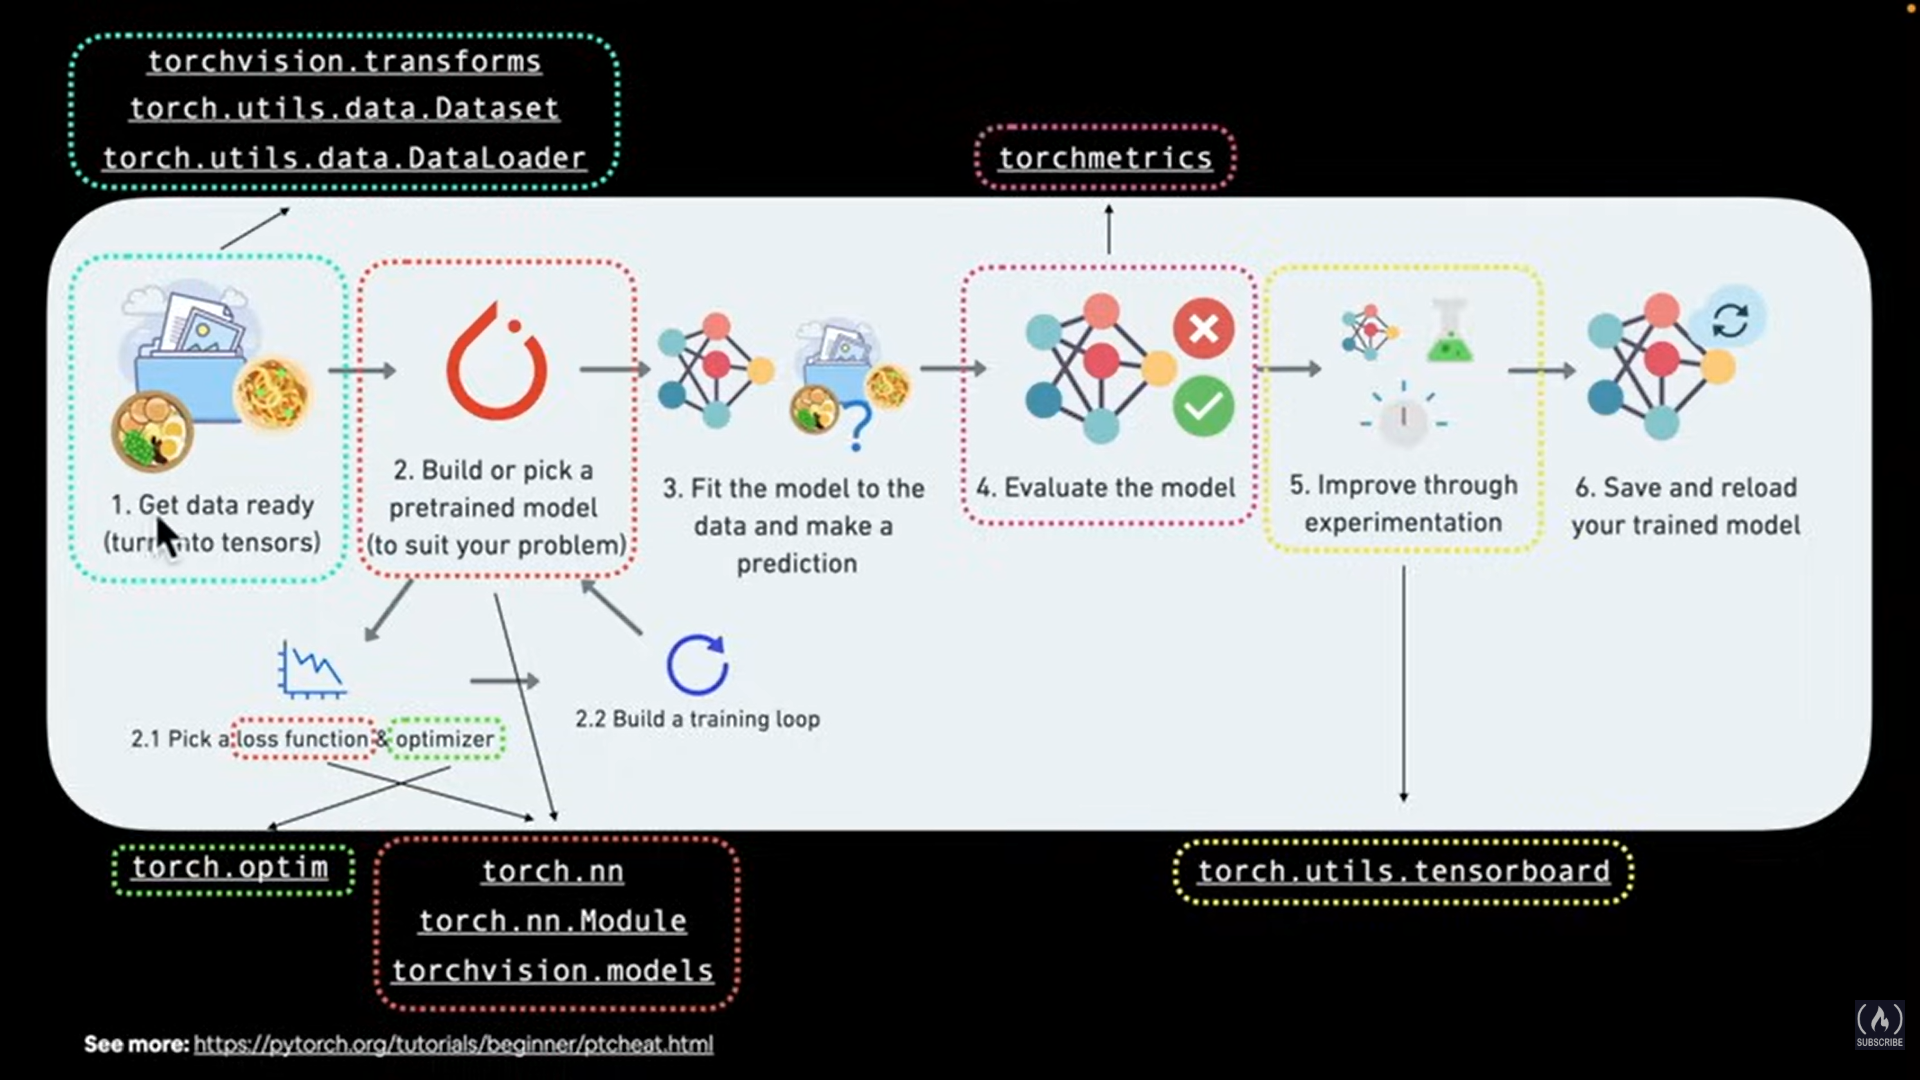

In [ ]:
# import pytorch and matplotlib
import torch
from torch import nn
import matplotlib.pyplot as plt

# check pytorch version
torch.__version__



'2.11.0+cpu'

create device-agnostic code

this menas if we have got acess to gpu , our code will use it (for potentially faster computing).

if no gpu then , the code will default to be using cpu

In [ ]:
# setup device agnostic code
device ="cuda" if torch.cuda.is_available() else "cpu"
print(f"using device : {device}")

using device : cpu


In [ ]:
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"CUDA version: {torch.version.cuda}")
print(f"GPU count: {torch.cuda.device_count()}")

CUDA available: False
CUDA version: None
GPU count: 0


In [ ]:
# create some data usijng the linear regressiong formula of y = weight *X +bias
weight = 0.7
bias = 0.3

#create range values
start = 0
end = 1
step =0.02

# create x and y (features and labels)
X = torch.arange(start,end,step).unsqueeze(dim =1)
y = weight * X + bias
X[:10],y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [ ]:
# split data
train_split = int(0.8 * len(X))
X_train , y_train =X[:train_split],y[:train_split]
X_test , y_test = X[train_split:], y[train_split:]
len(X_train), len(y_train), len(X_test), len(y_test)


(40, 40, 10, 10)

In [ ]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
  """
  plots training data, test data and compares predictions
  """
  plt.figure(figsize=(10,7)) #plt.figure() - Creates a new empty figure/window to draw on ,figsize=(10,7) - Sets the width to 10 inches and height to 7 inches

  #plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data") #plt.scatter() is a function that creates a scatter plot - it puts individual points on a graph based on their x and y coordinates.

  #plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data") #test_data → x-coordinates (position left/right) ,test_labels → y-coordinates (position up/down) ,c="g" → color = green ,s=4 → size = 4 pixels (dot size) ,label="Testing data" → name for the legend

  # are there predictions?
  if predictions is not None:
    # plot the predicitions if they exist
    plt.scatter(test_data, predictions, c="r", s=4, label="predicitions")

  plt.legend(prop={"size": 14});


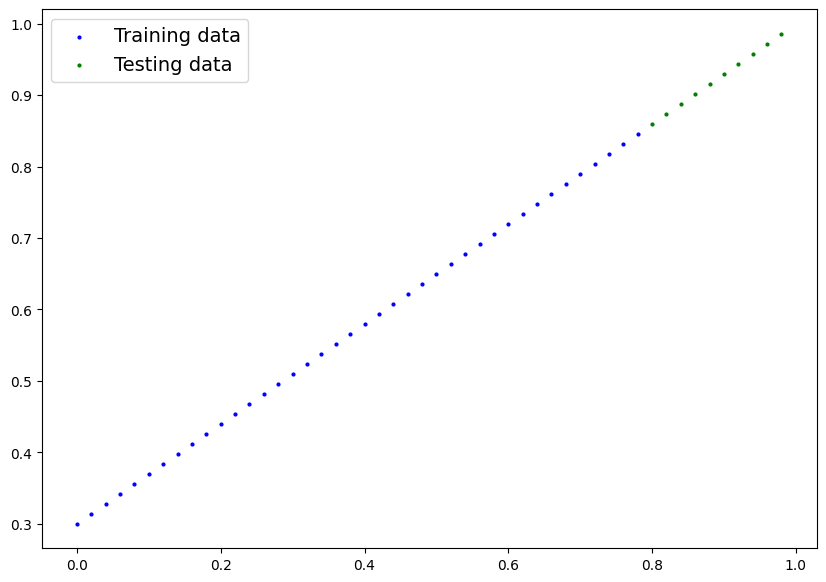

In [ ]:
# plot the data
# note if u dont have the plot_predictions() function loaded , this will error
plot_predictions(X_train , y_train , X_test, y_test)

## building the pytorch a linear model


In [ ]:
# Create a linear model by subclassing nn.Module
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        # Use nn.Linear() for creating the model parameters / also called: linear transform, product of weights and biases
        self.linear_layer = nn.Linear(in_features=1, out_features=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)

# Set the manual seed
torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
model_1, model_1.state_dict()

(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [ ]:
X_train[:5] , y_train[:5]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560]]))

In [ ]:
# setup loss function
loss_fn = nn.L1Loss()

# setup our optimizer
optimizer = torch.optim.SGD(params= model_1.parameters(),
                            lr=0.01)


In [ ]:
# let's write a training loop
torch.manual_seed(42)

epochs =200

# put data on the target device
X_train = X_train.to(device)
y_train = y_train.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

for epoch in range (epochs):
  model_1.train()

  # 1.Forward pass
  y_pred = model_1(X_train)

  # calculte the loss
  loss = loss_fn(y_pred, y_train)

  #3. optimizer zero grad
  optimizer.zero_grad()

  #4. perform backpropagation
  loss.backward()

  #5.optimizer step
  optimizer.step()

  ### testing
  model_1.eval()
  with torch.inference_mode():
    test_pred = model_1(X_test)
    test_loss = loss_fn(test_pred, y_test)

  # print out whats happening

  if epoch % 10 == 0:
    print(f"Epoch: {epoch} | Loss: {loss} | test loss : {test_loss} ")

Epoch: 0 | Loss: 0.5551779866218567 | test loss : 0.5739762187004089 
Epoch: 10 | Loss: 0.4399680495262146 | test loss : 0.4392663538455963 
Epoch: 20 | Loss: 0.3247582018375397 | test loss : 0.30455657839775085 
Epoch: 30 | Loss: 0.20954827964305878 | test loss : 0.16984674334526062 
Epoch: 40 | Loss: 0.09433844685554504 | test loss : 0.03513689711689949 
Epoch: 50 | Loss: 0.023886386305093765 | test loss : 0.04784906655550003 
Epoch: 60 | Loss: 0.0199567973613739 | test loss : 0.04580312222242355 
Epoch: 70 | Loss: 0.016517987474799156 | test loss : 0.0375305712223053 
Epoch: 80 | Loss: 0.013089170679450035 | test loss : 0.029944902285933495 
Epoch: 90 | Loss: 0.009653178043663502 | test loss : 0.02167237363755703 
Epoch: 100 | Loss: 0.006215679459273815 | test loss : 0.014086711220443249 
Epoch: 110 | Loss: 0.002787243574857712 | test loss : 0.005814164876937866 
Epoch: 120 | Loss: 0.0012645035749301314 | test loss : 0.013801807537674904 
Epoch: 130 | Loss: 0.0012645035749301314 | t

In [ ]:
model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]])),
             ('linear_layer.bias', tensor([0.3025]))])

In [ ]:
weight, bias

(0.7, 0.3)

### 6.4 Making and evaluuating predictions

In [ ]:
# turn model into evaluation mode
model_1.eval()

#make predictions on test data
with torch.inference_mode():
  y_preds = model_1(X_test)
y_preds

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]])

In [ ]:
device

'cpu'

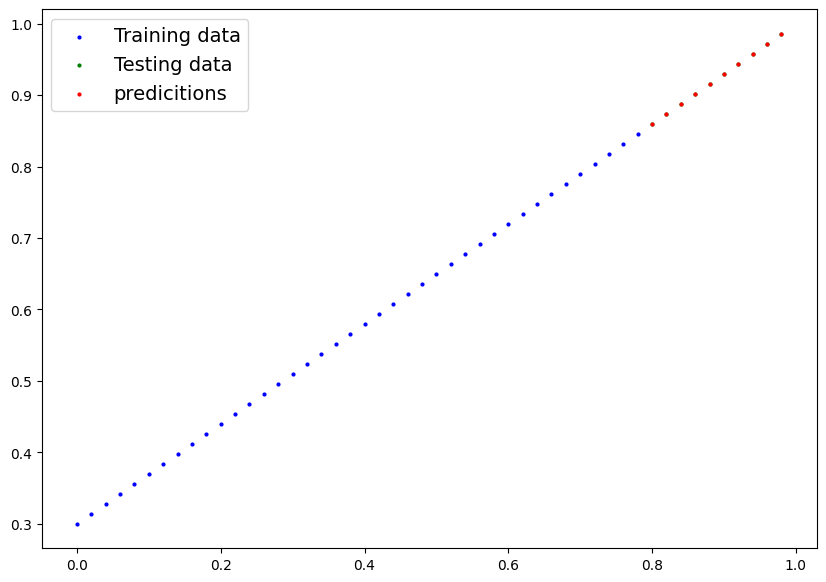

In [ ]:
#check out our model predictions visually
plot_predictions(predictions= y_preds)

## 6.5 saving and loading model

In [ ]:
from pathlib import Path

# create model directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents =  True , exist_ok = True )

# 2. create model save path
MODEL_NAME = "01_pytorch_workflow_model_1.pth"
MODEL_SAVE_PATH = MODEL_PATH /MODEL_NAME


# 3. Save the model state dict
print(f"Saving model to :{MODEL_SAVE_PATH}")
torch.save(obj =model_1.state_dict(),
           f = MODEL_SAVE_PATH)


MODEL_SAVE_PATH

Saving model to :models/01_pytorch_workflow_model_1.pth


PosixPath('models/01_pytorch_workflow_model_1.pth')

In [ ]:
model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]])),
             ('linear_layer.bias', tensor([0.3025]))])

In [ ]:
# Load a pytorch

#create a new instance of linear regression model v2
loaded_model_1 = LinearRegressionModelV2()

# load the saved model_1 state_dict
loaded_model_1.load_state_dict(torch.load(MODEL_SAVE_PATH))

# put the loaded model to device
loaded_model_1.to(device)

LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)

In [ ]:
next(loaded_model_1.parameters()).device

device(type='cpu')

In [ ]:
loaded_model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]])),
             ('linear_layer.bias', tensor([0.3025]))])

In [ ]:
# evaluate loaded model
loaded_model_1.eval()
with torch.inference_mode():
  loaded_model_1_preds = loaded_model_1(X_test)
y_preds == loaded_model_1_preds


tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])